## GPT2 Architecture Part 5: Transformer Block

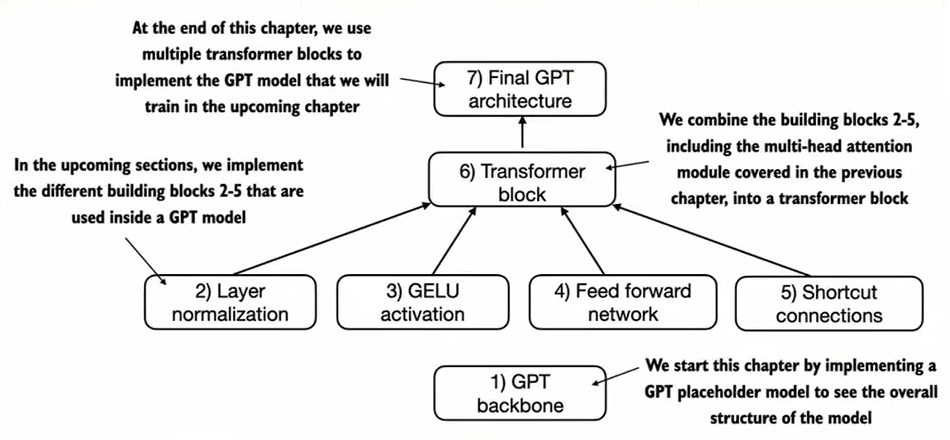

In [1]:
from IPython.display import Image
Image("images/stage_1_3_GELU/stages.png", width=800)

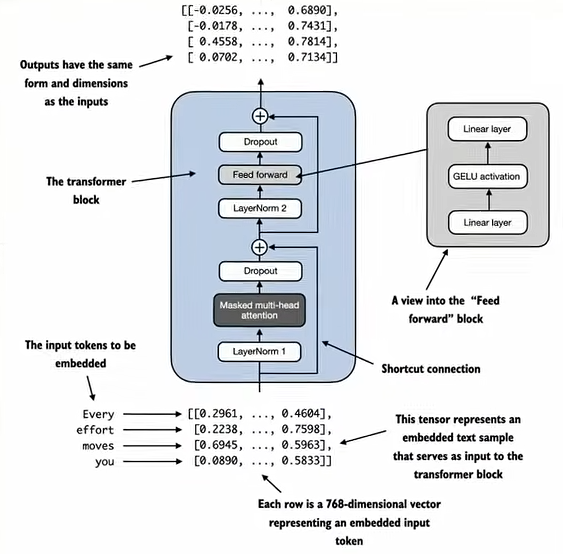

In [2]:
Image("images/stage_1_3_GELU/transformer_block.png", width=800)

In [3]:
import torch
import torch.nn as nn
torch.set_printoptions(sci_mode=False)



In [4]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size of the model
    "context_length": 1024,  # Maximum context length for the model
    "emb_dim": 768,          # Embedding dimension of the model
    "n_heads": 12,           # Number of attention heads in the model
    "n_layers": 12,          # Number of transformer layers in the model
    "drop_rate": 0.1,        # Dropout rate for regularization
    "qkv_bias": True         # Whether to include bias terms in the query, key, and value projections
}

### The Building Blocks: Layer Normalization, GELU and Feed-forward network

In [6]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)

        self.dropout = nn.Dropout(dropout)

        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))


    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # (b, num_tokens, d_out)
        queries = self.W_query(x)  # (b, num_tokens, d_out)
        values = self.W_value(x)  # (b, num_tokens, d_out)

        # we implicitly split the matrix by adding a new dimension for the heads "num_heads"
        # unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # transpose to get dimensions: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        # we wan th grouping to be the heads, so we swap the num_heads and num_tokens dimensions not on tokens

        keys = keys.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        queries = queries.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)
        values = values.transpose(1, 2)  # (b, num_heads, num_tokens, head_dim)

        # compute scaled dot product attention (aka slef attention) with a causal mask
        # we compute the attention scores by taking the dot product of the queries and keys
        attn_scores = queries @ keys.transpose(2, 3)  

        # original mask truncated to the number of tokens in the input and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # use the mask to fill the attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        # calculate the attention weights by applying softmax to the attention scores
        # # keys.shape[-1] is the head_dim, we scale the attention scores by the square root of the head dimension 
        # to prevent them from getting too large
        attn_weights = torch.softmax(attn_scores/keys.shape[-1]**0.5, dim=-1) 
        attn_weights = self.dropout(attn_weights)

        # calculate context vector as the weighted sum of the values, using the attention weights
        # transpose to keep num_heads & head_dim together for the output
        context_vec = (attn_weights @ values).transpose(1,2)

        # combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec




In [5]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True) # calculate row-wise mean
        var = x.var(dim=-1, keepdim=True, unbiased=False) # calculate row-wise variance
        x_norm = (x - mean) / torch.sqrt(var + self.eps) # eps is added to avoid division by zero
        return self.scale * x_norm + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))
    

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),  ## Expansion
            GELU(), ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])   ## Contraction
        )

    def forward(self, x):
        return self.layers(x)
    

### Let's Build entire Transformer Block

- Step 1: Shortcut connection for attention block

- Step 2: Shortcut connection for feed forward block

- Step 3: Add the original input back

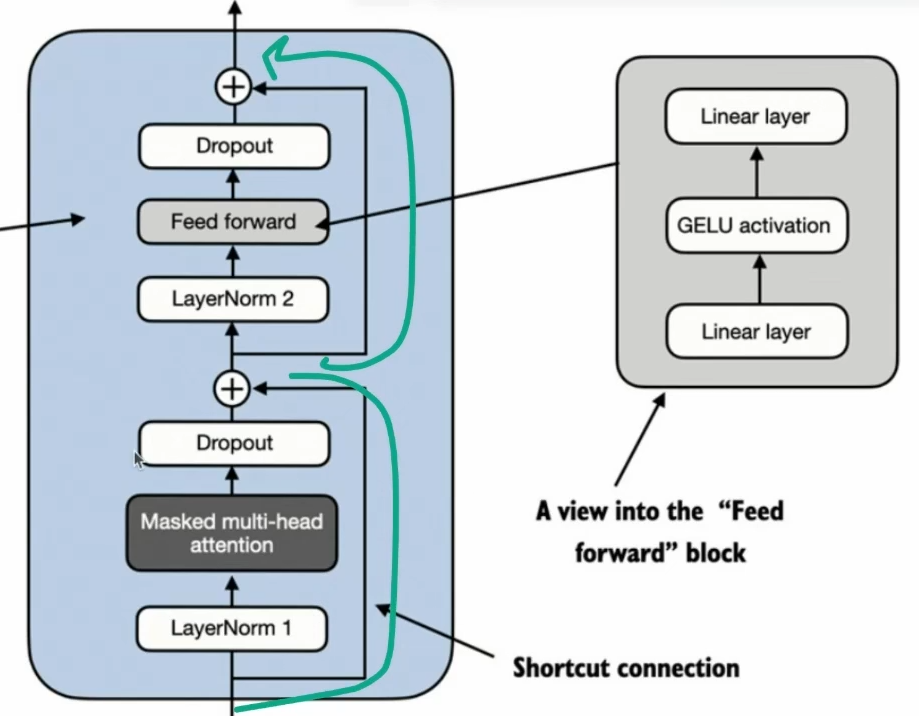

In [9]:
Image("images/stage_1_4_shortcut_conn/shorcut_in_transformer.png", width=700)

In [7]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
                    d_in=cfg["emb_dim"], 
                    d_out=cfg["emb_dim"], 
                    context_length=cfg["context_length"], 
                    num_heads=cfg["n_heads"], 
                    dropout=cfg["drop_rate"], 
                    qkv_bias=cfg["qkv_bias"])

        self.ff = FeedForward(cfg)

        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])

        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])
        


    def forward(self, x):
        # first part: layer_norm -> attention -> dropout -> add shortcut

        # shorcut connection for transformer block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # shape = (batch_size, num_tokens, emb_dim)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        # second part: layer_norm -> feedforward -> dropout -> add shortcut
        
        # shorcut connection for transformer block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # shortcut connection: Add the original input to the output of the attention layer

        return x



- Layer normalization is applied before each of 2 components, and dropout is applied after them to regularize the model and reduce overfitting.

- This is also known as Pre-LayerNorm

- Older architectures, such as original transformer model, appied layer normalizaion after the self-attention and feed-forward network instead, known as POST-LAYERNORM, which often leads to worse training dynamics.

- The class also implements the forward pass, where each component is followed by a shortcut connection that adds the input of the block to its output. This critical feature helps gradient flow through the network during training and improves the learnig of deep models.

#### Let's instaniate the Transformer object

In [8]:
torch.manual_seed(123)  # For reproducibility
x = torch.randn(2, 4, GPT_CONFIG_124M["emb_dim"])  # (batch_size, num_tokens, emb_dim)
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


<div class="alert alert-block alert-info" >

- The transformer block maintains the input dimension in its output, indicating that the TRANSFORMER architecture processes sequence of data without altering their shape throughout the network.

- The preservation of shape throughout the transformer block architecture is not incidental but a crucial aspect of its design.

- This design enables its effective application across a wide range of dsequence-to-sequence tasks, where each vector directly corresponds to an input vector, maintaning a one-to-one relationship.


- However, the output is a context vector that encapsulates information from the entire input sequence.

- This means that, while the physical dimensions of the sequence (length and feature size) remqins unchanges as it passes through the transformer block, the content of each output vector is re-encoded to integrate the contextual information from across the input sequence.

</div>